# Super Artillery: From Calculus to Intelligent Aiming

### Mathematical Modeling, Numerical Simulation, and Gradient-Based Optimization

**Course:** Math Concepts for Developers — SoftUni  
**Project Type:** Applied Mathematics and Numerical Methods  
**Programming Language:** Python  
**Date:** November 2026

---

*A mathematical investigation inspired by classic artillery MS-DOS games, with applications to projectile motion simulation and automatic aiming.*

## Abstract

This project investigates the application of mathematical modeling, numerical methods, and optimization techniques to projectile motion.

Inspired by classic artillery MS-DOS games, the study focuses on a practical problem: predicting the trajectory of a launched object and determining the launch angle required to reach a specified target.

An analytical model is used as a reference for evaluating numerical accuracy. Euler's method is employed to approximate projectile motion, while Gradient Descent is investigated as an iterative approach to automatic aiming.

The study compares mathematical solutions with numerical approximations and evaluates the influence of time-step size, learning rate, and initial conditions.

The project aims to demonstrate not only how these mathematical methods work, but also why they are suitable for the selected problem and what limitations they introduce.

## 1. Introduction

### 1.1 Background and Motivation

The idea for this project was inspired by an old DOS game called Super Artillery, which I found incredibly interesting and fun to play. The game involved launching projectiles at targets by adjusting the angle and taking factors such as distance and wind into account.

What fascinated me was how a seemingly simple game could involve so much mathematics. Behind every shot, there are calculations related to angles, velocity, gravity, and the trajectory of a moving object.

This made me curious about how the same mathematical principles are used beyond computer games — from predicting projectile motion in physics to controlling robotic ball launchers that need to aim at a specific target.

Through this project, I wanted to explore these connections and understand how calculus, numerical methods, and optimization algorithms can turn a simple idea from a childhood computer game into a practical mathematical problem.

### 1.2 Problem Statement

In a classic artillery game, hitting a target is not simply a matter of choosing the right angle. The trajectory of a projectile depends on several physical factors, including launch velocity, gravity, wind, air resistance, and the relative position of the target.

This raises an interesting question: Can we use mathematics to predict where a projectile will land and automatically calculate the launch angle needed to hit a target under different physical conditions?

To explore this problem, the project aims to:

1. Develop a mathematical model of projectile motion based on fundamental physical principles.

2. Investigate how launch angle, initial velocity, and gravity affect the trajectory.

3. Use Euler's numerical method to simulate projectile motion and evaluate its accuracy.

4. Apply Gradient Descent to find a launch angle that minimizes the distance between the landing position and the target.

5. Explore how additional physical factors, such as wind and air resistance, could influence the trajectory and the choice of mathematical methods.

6. Compare the selected mathematical approaches with alternative methods and discuss their advantages and limitations.

The investigation begins with a simplified model without wind or air resistance. This provides an analytical reference against which numerical results can be evaluated. More realistic physical conditions are considered as a possible extension of the model.

### 1.3 Research Question

**How accurately can numerical methods simulate projectile motion, and how effectively can Gradient Descent determine a launch angle to hit a specified target?**

The project investigates this question through three more specific research questions:

### 1.4 Research Sub-questions

**RQ1 — Numerical Accuracy:** How does the time-step size affect the accuracy of Euler's method compared with the analytical solution?

**RQ2 — Automatic Aiming:** Can Gradient Descent determine a launch angle that minimizes the difference between the projectile's landing position and a specified target?

**RQ3 — Optimization Behavior:** How do the learning rate and initial launch angle affect Gradient Descent convergence?

### 1.5 Research Hypotheses

The following hypotheses will be tested through numerical experiments:

**H1:** Decreasing the time-step size generally improves the accuracy of Euler's method when simulating projectile motion.

**H2:** Gradient Descent can minimize the target distance error for a reachable target under suitable optimization settings.

**H3:** The learning rate and initial launch angle influence the convergence behavior of Gradient Descent.

These hypotheses will be evaluated using numerical results, graphical visualizations, and comparisons with analytical solutions.

### 1.6 Scope and Assumptions

To keep the mathematical analysis clear and the experiments reproducible, the project begins with an idealized two-dimensional projectile-motion model.

The main assumptions are:

- Constant gravitational acceleration.
- Flat terrain.
- No air resistance or wind.
- Constant initial launch speed.
- Equal launch and landing heights.

These assumptions make it possible to derive an analytical solution and use it as a reference for evaluating numerical methods.

In real-world conditions, factors such as wind, air resistance, launch height, and projectile properties can significantly affect the trajectory. Including these effects would make the model more realistic but also more mathematically complex.

The project therefore focuses first on understanding and validating the fundamental mathematical methods. The inclusion of wind and air resistance is considered a possible extension, depending on the available development time.

Although the mathematical model is based on physical principles, the project does not include experimental measurements from a real ball-launching system. Its results should therefore be interpreted as a numerical investigation rather than a validated real-world prediction.

### 1.7 Expected Contribution

The main contribution of this project is not the development of a new mathematical algorithm, but the practical application and comparison of established mathematical methods within a single, understandable problem.

By combining analytical modeling, numerical simulation, and optimization, the project aims to demonstrate:

- How mathematical theory can be translated into working Python code.

- How numerical accuracy can be measured and evaluated.

- How optimization algorithms can be used to solve an automatic aiming problem.

- Why different mathematical methods are suitable for different aspects of the same problem.

- How a simple idea inspired by a computer game can lead to a meaningful investigation of mathematics and its practical applications.

# 2. Previous Work

Projectile motion is a classical problem in physics and applied mathematics. Over time, different mathematical approaches have been developed to describe the movement of objects, predict their trajectories, and solve problems involving launch angles, velocities, and target positions.

These approaches range from analytical equations derived from Newton's laws of motion to numerical simulations and optimization algorithms.

Understanding these existing methods provides a foundation for selecting the mathematical techniques used in this project.

### 2.1 Classical Projectile Motion

The mathematical description of projectile motion is based on Newton's laws of motion and the principles of classical mechanics. [1], [2]

In the simplest model, an object is launched with an initial velocity at a given angle and moves under the influence of gravity.

When air resistance is ignored, horizontal and vertical motion can be studied independently:

- **Horizontal motion:** The horizontal velocity remains constant because no horizontal force acts on the projectile.
- **Vertical motion:** The vertical velocity changes continuously due to gravitational acceleration.

This allows the trajectory to be described using analytical equations derived from calculus.

For an initial velocity $v_0$, launch angle $\theta$, and gravitational acceleration $g$, the position at time $t$ is:

$$
x(t) = v_0 \cos(\theta)t
$$

$$
y(t) = v_0 \sin(\theta)t - \frac{1}{2}gt^2
$$

These equations provide an exact solution within the assumptions of the idealized model.

However, real-world projectile motion can be affected by additional forces, including air resistance and wind. In such cases, the equations of motion become more complex, and a simple analytical solution may no longer be available.

**Example: Projectile Trajectory**

To illustrate the analytical equations, consider a projectile launched with the following parameters:

- Initial velocity: $v_0 = 20$ m/s
- Launch angle: $\theta = 45^\circ$
- Gravitational acceleration: $g = 9.81$ m/s²
- Initial position: $(0, 0)$

Using the analytical equations, we can calculate the projectile's position at different moments and visualize its trajectory.

This example provides an intuitive illustration of the mathematical model before introducing numerical approximation methods.

**Time of Flight**

For a projectile launched and landing at the same height, the total flight time can be calculated by setting the vertical position $y(t)$ equal to zero and solving for the positive time value:

$$
T = \frac{2v_0\sin(\theta)}{g}
$$

This formula determines the time interval used to generate the analytical trajectory.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Example parameters
v0 = 20.0                  # Initial velocity (m/s)
theta_deg = 45.0           # Launch angle (degrees)
g = 9.81                   # Gravitational acceleration (m/s^2)

theta = np.radians(theta_deg)

# Total flight time for equal launch and landing heights
flight_time = 2 * v0 * np.sin(theta) / g

# Calculate trajectory
t = np.linspace(0, flight_time, 201)

x = v0 * np.cos(theta) * t
y = v0 * np.sin(theta) * t - 0.5 * g * t**2

# Calculate theoretical range and maximum height
projectile_range = v0**2 * np.sin(2 * theta) / g
max_height = (v0 * np.sin(theta))**2 / (2 * g)

print(f"Flight time: {flight_time:.2f} s")
print(f"Horizontal range: {projectile_range:.2f} m")
print(f"Maximum height: {max_height:.2f} m")

# Select 5 equally spaced points from the trajectory
sample_times = t[::50]
sample_x = x[::50]
sample_y = y[::50]

print("\nSample trajectory positions")
print(f"{'Time (s)':>10} {'X (m)':>12} {'Y (m)':>12}")

for ti, xi, yi in zip(sample_times, sample_x, sample_y):
    print(f"{ti:10.2f} {xi:12.2f} {yi:12.2f}")


Flight time: 2.88 s
Horizontal range: 40.77 m
Maximum height: 10.19 m

Sample trajectory positions
  Time (s)        X (m)        Y (m)
      0.00         0.00         0.00
      0.72        10.19         7.65
      1.44        20.39        10.19
      2.16        30.58         7.65
      2.88        40.77         0.00


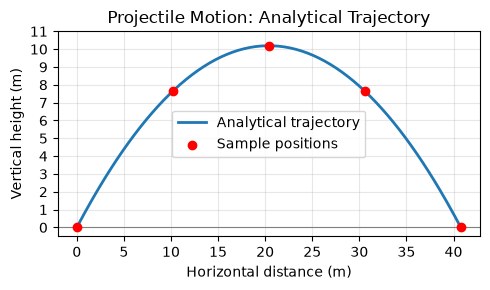

In [8]:

plt.figure(figsize=(5, 3))

plt.plot(x, y, label="Analytical trajectory", linewidth=2)
plt.scatter(sample_x, sample_y, color="red",
            label="Sample positions", zorder=3)

plt.title("Projectile Motion: Analytical Trajectory")
plt.xlabel("Horizontal distance (m)")
plt.ylabel("Vertical height (m)")

plt.yticks(np.arange(0, 12, 1))  # Y-axis ticks every 1 meter

plt.axhline(0, color="gray", linewidth=0.8)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


### 2.2 Numerical Methods for Motion Simulation

Numerical methods provide an alternative approach to solving mathematical problems, especially when analytical solutions are difficult or impossible to obtain.

Instead of calculating the complete trajectory directly from a formula, numerical methods approximate the motion of an object step by step, using small time intervals.

One of the simplest numerical integration techniques is **Euler's Method**, which approximates the next state of a system using its current state and rate of change.

For a general differential equation:

$$
\frac{dy}{dt} = f(t,y)
$$

Euler's method estimates the next value as:

$$
y_{n+1} = y_n + h f(t_n,y_n)
$$

where:

- $y_n$ is the current value.
- $h$ is the time-step size.
- $f(t_n,y_n)$ represents the rate of change at the current step.
- $y_{n+1}$ is the estimated value at the next step.

For projectile motion, Euler's method can be applied to both position and velocity. At each time step, the projectile's position is updated using its current velocity, while its velocity is updated using acceleration. [3]

The accuracy of Euler's method depends strongly on the selected time step. Smaller steps generally reduce the numerical error, but require more calculations.

Euler's method is a **first-order numerical method**, meaning that its global approximation error is generally proportional to the time-step size under suitable conditions.

More advanced techniques, such as the **Runge–Kutta methods**, can provide higher accuracy for a given time step, although they require more calculations per step.

In this project, Euler's method is selected because it is straightforward to implement, easy to understand, and suitable for investigating the relationship between time-step size and numerical accuracy.

The analytical projectile model introduced in Section 2.1 will be used as a reference to evaluate the numerical results.

### 2.3 Optimization and Automatic Aiming

Predicting the trajectory of a projectile is only one part of the problem. Another challenge is determining the launch angle required to reach a specific target.

This can be formulated as an **optimization problem**, where the objective is to minimize the difference between the projectile's predicted landing position and the target distance.

For an ideal projectile launched and landing at the same height, the horizontal range is:

$$
R(\theta) = \frac{v_0^2 \sin(2\theta)}{g}
$$

where:

- $R(\theta)$ is the horizontal range.
- $v_0$ is the initial velocity.
- $\theta$ is the launch angle.
- $g$ is the gravitational acceleration.

If the target is located at a horizontal distance $D$, we can define a **loss function**:

$$
E(\theta) = \left(R(\theta) - D\right)^2
$$

The goal is to find a launch angle that minimizes this error.

One approach is **Gradient Descent**, an iterative optimization algorithm that uses derivatives to determine how a parameter should be adjusted to reduce the loss. [4]

The general update rule is:

$$
\theta_{n+1} = \theta_n - \alpha \frac{dE}{d\theta}
$$

where:

- $\theta_n$ is the current launch angle.
- $\alpha$ is the learning rate, which controls the size of each adjustment.
- $\frac{dE}{d\theta}$ is the derivative of the loss function with respect to the angle.
- $\theta_{n+1}$ is the updated launch angle.

The learning rate plays an important role in the optimization process. If it is too small, convergence may be slow. If it is too large, the algorithm may overshoot the solution or fail to converge.

The initial launch angle can also influence the result, because the loss function may have multiple stationary points or more than one valid solution.

For the ideal projectile model, the launch angle can also be calculated analytically when the target is reachable. Numerical root-finding methods, such as bisection or Newton's method, provide other possible approaches.

These alternatives may be more efficient for this simplified problem. However, Gradient Descent is selected because it allows us to investigate derivative-based optimization, convergence behavior, and the influence of algorithm parameters.

The detailed mathematical derivation, Python implementation, and experimental evaluation of Gradient Descent will be presented in the following sections.

### 2.4 Practical Applications

The mathematical principles behind projectile motion are used in a variety of real-world applications, including physics education, robotics, sports analysis, and computer simulations.

Although these applications may involve more complex physical conditions, they share the same fundamental challenge: predicting how an object moves and determining the parameters that influence its trajectory.

Some examples include:

- **Physics education:** Interactive simulations help students understand how launch angle, initial velocity, and gravity affect the trajectory of a moving object.
- **Robotic ball launchers:** Automated launching systems can use mathematical models to estimate suitable launch angles and velocities for reaching a target.
- **Sports analysis:** Projectile motion models can help explain the trajectories of balls in sports such as basketball, football, and tennis.
- **Computer games:** Physics simulations use mathematical equations and numerical techniques to model moving objects and their interactions with the environment.
- **Engineering simulations:** Numerical methods are used to approximate the behavior of physical systems described by differential equations.

In real-world situations, factors such as air resistance, wind, rotation, and measurement uncertainty can significantly influence the results. Therefore, more advanced models and numerical techniques may be necessary to achieve accurate predictions.

The simplified projectile model used in this project provides a foundation for understanding these applications. By combining analytical calculations, numerical simulation, and optimization, **Super Artillery** demonstrates mathematical concepts that can also be applied to more complex physical problems.

### 2.5 Connection to This Project

The mathematical approaches discussed in the previous sections provide the foundation for the Super Artillery project.

Classical mechanics allows projectile motion to be described analytically, while numerical methods offer an alternative way to simulate trajectories. Optimization techniques introduce the possibility of automatically determining launch parameters to reach a target.

This project combines three complementary approaches:

1. **Analytical Modeling:** Provides an exact reference solution for projectile motion under idealized conditions.

2. **Euler's Method:** Approximates projectile motion through discrete time steps, allowing the relationship between step size and numerical accuracy to be investigated.

3. **Gradient Descent:** Uses derivatives to iteratively adjust the launch angle and minimize the difference between the predicted landing position and the target distance.

The analytical solution will serve as a reference for evaluating the numerical simulation, while Gradient Descent will be examined in terms of accuracy, convergence, and sensitivity to algorithm parameters.

The purpose of this project is not to develop a new mathematical algorithm, but to demonstrate how established mathematical methods can be combined to solve a practical problem.

The following section, **3. Methods**, presents the mathematical derivations, implementation details, and experimental approach used in the investigation.

## 3. Methods

This section describes the mathematical models, numerical algorithms, and optimization techniques used in the Super Artillery project.

The methodology combines an analytical solution of projectile motion, Euler's numerical integration method, and Gradient Descent for automatic aiming.

The analytical model provides a reference for evaluating numerical accuracy, while the optimization algorithm is used to investigate how launch parameters can be adjusted to reach a target.

### 3.1 Mathematical Model and Assumptions

The system represents a projectile launched from a fixed position with an initial velocity and launch angle.

The projectile moves in a two-dimensional coordinate system, where the horizontal axis represents distance and the vertical axis represents height.

To keep the mathematical model simple and allow direct comparison between analytical and numerical solutions, the following assumptions are made:

- Gravitational acceleration is constant: $g = 9.81$ m/s².
- Air resistance and wind are ignored.
- The projectile is treated as a point mass.
- The launch and landing positions are at the same height.
- The initial position is $(x_0, y_0) = (0, 0)$.
- The initial speed remains fixed during each experiment, while the launch angle may vary.

The initial velocity is divided into horizontal and vertical components:

$$
v_{x,0} = v_0\cos(\theta)
$$

$$
v_{y,0} = v_0\sin(\theta)
$$

According to Newton's Second Law, gravity produces a constant downward acceleration. Since no horizontal force acts on the projectile, the acceleration components are:

$$
a_x = 0
$$

$$
a_y = -g
$$

The model can therefore be expressed as a system of first-order differential equations:

**1. Horizontal position**

$$
\frac{dx}{dt} = v_x
$$

The horizontal position changes according to the horizontal velocity.

**2. Vertical position**

$$
\frac{dy}{dt} = v_y
$$

The vertical position changes according to the vertical velocity.

**3. Horizontal velocity**

$$
\frac{dv_x}{dt} = 0
$$

The horizontal velocity remains constant because there is no horizontal acceleration.

**4. Vertical velocity**

$$
\frac{dv_y}{dt} = -g
$$

The vertical velocity decreases by 9.81 m/s every second due to gravity.

These equations form the mathematical foundation for both the analytical solution and Euler's numerical method.

All calculations use SI units: meters for distance, seconds for time, and meters per second for velocity. Angles are converted to radians when used in Python's trigonometric functions.

### 3.2 Analytical Solution of Projectile Motion

The analytical solution describes the projectile's motion using mathematical equations derived from the differential equations introduced in Section 3.1.

Since gravitational acceleration is constant and air resistance is ignored, the equations can be solved directly using integration.

The analytical solution will serve as a reference for evaluating the accuracy of Euler's numerical method.

#### 3.2.1 Position and Velocity Equations

The initial velocity is divided into horizontal and vertical components:

$$
v_{x,0} = v_0\cos(\theta)
$$

$$
v_{y,0} = v_0\sin(\theta)
$$

Since horizontal acceleration is zero, horizontal velocity remains constant:

$$
v_x(t) = v_0\cos(\theta)
$$

Vertical acceleration is equal to $-g$. Integrating acceleration with respect to time gives:

$$
v_y(t) = v_0\sin(\theta) - gt
$$

Integrating the velocity equations and using the initial position $(0,0)$ gives the projectile's coordinates:

$$
x(t) = v_0\cos(\theta)t
$$

$$
y(t) = v_0\sin(\theta)t - \frac{1}{2}gt^2
$$

These equations allow the position of the projectile to be calculated at any time during its flight.

#### 3.2.2 Time of Flight

The total flight time is the time between launch and landing.

Since the projectile starts and lands at the same height, the vertical position at landing is zero:

$$
y(T) = 0
$$

Substituting the vertical position equation:

$$
0 = v_0\sin(\theta)T - \frac{1}{2}gT^2
$$

Factoring out $T$:

$$
T\left(v_0\sin(\theta)-\frac{1}{2}gT\right)=0
$$

The first solution, $T=0$, represents the launch moment.

The second solution gives the total flight time:

$$
\boxed{T = \frac{2v_0\sin(\theta)}{g}}
$$

This formula is valid for a projectile launched upward at an angle between $0^\circ$ and $90^\circ$, assuming equal launch and landing heights.

#### 3.2.3 Maximum Height

The projectile reaches its maximum height when its vertical velocity becomes zero:

$$
v_y(t)=0
$$

Using the vertical velocity equation:

$$
0=v_0\sin(\theta)-gt
$$

The time required to reach the highest point is:

$$
t_{\max}=\frac{v_0\sin(\theta)}{g}
$$

Substituting this value into the vertical position equation gives:

$$
H_{\max}=v_0\sin(\theta)t_{\max}-\frac12gt_{\max}^2
$$

After simplification:

$$
\boxed{H_{\max}=\frac{v_0^2\sin^2(\theta)}{2g}}
$$

This equation shows that maximum height depends on the initial speed and the vertical component of the launch angle.

#### 3.2.4 Horizontal Range

The horizontal range is the total horizontal distance traveled before the projectile returns to the ground.

It can be calculated by substituting the total flight time into the horizontal position equation:

$$
R=x(T)=v_0\cos(\theta)T
$$

Using the flight-time formula:

$$
R=v_0\cos(\theta)\frac{2v_0\sin(\theta)}{g}
$$

Applying the trigonometric identity:

$$
2\sin(\theta)\cos(\theta)=\sin(2\theta)
$$

We obtain:

$$
\boxed{R(\theta)=\frac{v_0^2\sin(2\theta)}{g}}
$$

For a fixed initial speed, the maximum horizontal range occurs at a launch angle of $45^\circ$.

This relationship is particularly important for the automatic aiming problem, where the objective is to determine an angle that allows the projectile to reach a specified target distance.

#### 3.2.5 Numerical Example and Verification

To verify the analytical formulas derived above, we use the same initial parameters as in Section 2.1:

- Initial velocity: $v_0 = 20$ m/s
- Launch angle: $\theta = 45^\circ$
- Gravitational acceleration: $g = 9.81$ m/s²

The calculated results are summarized below:

| Quantity | Analytical Formula | Calculated Value |
|---|---|---|
| Flight time | $T = \frac{2v_0\sin(\theta)}{g}$ | 2.88 s |
| Maximum height | $H_{\max} = \frac{v_0^2\sin^2(\theta)}{2g}$ | 10.19 m |
| Horizontal range | $R = \frac{v_0^2\sin(2\theta)}{g}$ | 40.77 m |

These values are consistent with the results calculated using Python in Section 2.1, where the analytical trajectory was also visualized.

This confirms that the formulas derived in this section reproduce the expected results for the selected initial conditions.

The analytical solution will serve as a reference for evaluating Euler's numerical method in the following sections.


#### 3.2.5 Role of the Analytical Solution

The analytical equations provide an exact reference within the assumptions of the idealized physical model.

They will be used in two important parts of the project:

1. **Numerical validation:** Comparing Euler's approximate trajectory with the analytical trajectory to measure numerical error.
2. **Automatic aiming:** Calculating the horizontal range as a function of the launch angle and defining the optimization objective for Gradient Descent.

The analytical solution therefore connects the physical model, numerical simulation, and optimization methods investigated in this project.

### 3.3 Euler's Method for Projectile Simulation

Euler's method is a numerical integration technique used to approximate solutions of differential equations.

Unlike the analytical approach, which calculates the projectile's position directly at a given time, Euler's method estimates the motion step by step using the current position, velocity, and acceleration.

#### 3.3.1 Derivation of Euler's Method

The derivative of a function describes its instantaneous rate of change:

$$
\frac{dy}{dt} = f(t,y)
$$

For a small time step $h$, the derivative can be approximated using a forward difference:

$$
\frac{dy}{dt} \approx \frac{y(t+h)-y(t)}{h}
$$

Rearranging this expression gives:

$$
y(t+h) \approx y(t)+h f(t,y)
$$

In discrete form, Euler's method becomes:

$$
\boxed{y_{n+1}=y_n+h f(t_n,y_n)}
$$

where:

- $y_n$ is the current value.
- $y_{n+1}$ is the estimated value at the next time step.
- $h$ is the time-step size.
- $f(t_n,y_n)$ is the rate of change at the current step.

The method assumes that the rate of change remains approximately constant over each small interval.

Reducing the time-step size generally improves accuracy, but increases the number of calculations required.

#### 3.3.2 Applying Euler's Method to Projectile Motion

The projectile is described by four differential equations introduced in Section 3.1:

$$
\frac{dx}{dt}=v_x,\qquad
\frac{dy}{dt}=v_y
$$

$$
\frac{dv_x}{dt}=0,\qquad
\frac{dv_y}{dt}=-g
$$

Applying Euler's method to each equation gives:

**Horizontal position:**

$$
x_{n+1}=x_n+h v_{x,n}
$$

The new horizontal position is estimated using the current horizontal velocity.

**Vertical position:**

$$
y_{n+1}=y_n+h v_{y,n}
$$

The new vertical position is estimated using the current vertical velocity.

**Horizontal velocity:**

$$
v_{x,n+1}=v_{x,n}
$$

The horizontal velocity remains constant because horizontal acceleration is zero.

**Vertical velocity:**

$$
v_{y,n+1}=v_{y,n}-gh
$$

The vertical velocity decreases due to gravitational acceleration.

The initial conditions are:

$$
x_0=0,\qquad y_0=0
$$

$$
v_{x,0}=v_0\cos(\theta),\qquad
v_{y,0}=v_0\sin(\theta)
$$

At every time step, the algorithm calculates the next position and velocity from the current state.

This approach is known as **Explicit Euler's Method**, because all updates use values from the previous step.

#### 3.3.3 Numerical Error

Euler's method introduces approximation error because it replaces continuous motion with discrete updates.

For sufficiently smooth functions, the local truncation error is of order $O(h^2)$, while the global error over a fixed time interval is generally of order $O(h)$.

This means that reducing the time-step size typically reduces the accumulated numerical error.

In projectile motion, the error is especially visible in the vertical position because vertical velocity changes continuously under gravity.

The analytical solution from Section 3.2 provides a reference for measuring this error.

The effect of different time-step sizes will be investigated in Section 4, Evaluation.

In [9]:

import numpy as np

def simulate_euler(v0, angle_deg, h, g=9.81):
    """
    Simulate ideal projectile motion using Explicit Euler's Method.

    Parameters
    ----------
    v0 : float
        Initial speed in m/s.
    angle_deg : float
        Launch angle in degrees.
    h : float
        Time-step size in seconds.
    g : float
        Gravitational acceleration in m/s^2.

    Returns
    -------
    times, xs, ys : numpy.ndarray
        Time and position arrays, including an interpolated
        landing point at ground level.
    """
    if v0 <= 0 or h <= 0 or g <= 0:
        raise ValueError("Speed, time step and gravity must be positive.")
    if not 0 < angle_deg < 90:
        raise ValueError("Launch angle must be between 0 and 90 degrees.")

    theta = np.radians(angle_deg)

    # Initial conditions
    t = 0.0
    x = 0.0
    y = 0.0

    vx = v0 * np.cos(theta)
    vy = v0 * np.sin(theta)

    times = [t]
    xs = [x]
    ys = [y]

    while True:
        # Explicit Euler updates using the current state
        x_next = x + vx * h
        y_next = y + vy * h

        vx_next = vx
        vy_next = vy - g * h
        t_next = t + h

        # Detect when the projectile crosses ground level
        if y_next < 0:
            # Linear interpolation to estimate the landing point
            fraction = y / (y - y_next)

            times.append(t + fraction * h)
            xs.append(x + fraction * (x_next - x))
            ys.append(0.0)
            break

        times.append(t_next)
        xs.append(x_next)
        ys.append(y_next)

        t, x, y = t_next, x_next, y_next
        vx, vy = vx_next, vy_next

    return np.array(times), np.array(xs), np.array(ys)


In [10]:

# Example parameters
v0 = 20.0
angle_deg = 45.0
h = 0.1
g = 9.81

euler_t, euler_x, euler_y = simulate_euler(
    v0=v0,
    angle_deg=angle_deg,
    h=h,
    g=g
)

print(f"Time step: {h} s")
print(f"Number of simulated intervals: {len(euler_t) - 1}")
print(f"Estimated flight time: {euler_t[-1]:.4f} s")
print(f"Estimated horizontal range: {euler_x[-1]:.4f} m")
print(f"Maximum sampled height: {np.max(euler_y):.4f} m")


Time step: 0.1 s
Number of simulated intervals: 30
Estimated flight time: 2.9827 s
Estimated horizontal range: 42.1822 m
Maximum sampled height: 10.9127 m


In [11]:

# Display the first 10 simulation steps and the landing point

print(f"{'Step':<8} {'Time (s)':<12} {'X (m)':<12} {'Y (m)':<12}")
print("-" * 44)

# First 10 steps
for i in range(min(10, len(euler_t))):
    print(f"{i:<8} {euler_t[i]:<12.3f} {euler_x[i]:<12.3f} {euler_y[i]:<12.3f}")

# Final landing point
print("...")
i = len(euler_t) - 1
print(f"{i:<8} {euler_t[i]:<12.3f} {euler_x[i]:<12.3f} {euler_y[i]:<12.3f}")


Step     Time (s)     X (m)        Y (m)       
--------------------------------------------
0        0.000        0.000        0.000       
1        0.100        1.414        1.414       
2        0.200        2.828        2.730       
3        0.300        4.243        3.948       
4        0.400        5.657        5.068       
5        0.500        7.071        6.090       
6        0.600        8.485        7.014       
7        0.700        9.899        7.839       
8        0.800        11.314       8.567       
9        0.900        12.728       9.196       
...
30       2.983        42.182       0.000       


The table shows the first ten steps of the Euler simulation and the final landing point.

Each row represents a numerical approximation of the projectile's position at a specific time.

The intermediate steps are omitted for readability, but all calculated positions are retained in the simulation arrays.

This step-by-step representation illustrates how Euler's method approximates continuous projectile motion through discrete time intervals.

#### Comparison with the Analytical Results

The results obtained using Euler's method differ slightly from the analytical results presented in Sections 2.1 and 3.2, even though the same initial conditions are used.

The analytical solution calculates the projectile's position using exact mathematical formulas within the assumptions of the idealized model.

In contrast, Euler's method approximates the motion using discrete time steps. At each step, the algorithm assumes that the current velocity remains constant over the entire time interval.

Because gravity continuously changes the vertical velocity, this approximation introduces numerical error that accumulates during the simulation.

For the selected time step of $h = 0.1$ seconds, Euler's method slightly overestimates the projectile's vertical position, resulting in a longer estimated flight time and horizontal range.

**This difference is expected and does not indicate an error in the implementation.**

Reducing the time-step size should improve the accuracy of the numerical solution and bring the results closer to the analytical values.

This hypothesis will be tested systematically in Section 4, Evaluation.

### 3.4 Gradient Descent for Automatic Aiming

Gradient Descent is an iterative optimization algorithm used to minimize a mathematical function.

In this project, Gradient Descent is applied to the automatic aiming problem: finding a launch angle that allows the projectile to reach a specified target distance.

The initial speed is fixed, while the launch angle is adjusted during optimization.

#### 3.4.1 Defining the Optimization Problem

The main objective of automatic aiming is to determine the launch angle that allows the projectile to reach a target at a known horizontal distance.

In this experiment, we know:

- The initial speed of the projectile, $v_0$.
- The gravitational acceleration, $g$.
- The horizontal distance to the target, $D$.

The unknown variable is the launch angle, $\theta$.

**Step 1: Calculate the horizontal range**

From Section 3.2, the horizontal range is:

$$
\boxed{R(\theta)=\frac{v_0^2\sin(2\theta)}{g}}
$$

Here, $R(\theta)$ represents the distance traveled by the projectile before landing.

For a fixed initial speed and constant gravity, the range depends only on the launch angle.

For example, with an initial speed of $20$ m/s:

$$
R(\theta)=\frac{20^2}{9.81}\sin(2\theta)
$$

$$
R(\theta)\approx40.77\sin(2\theta)
$$

The maximum possible range is approximately $40.77$ meters, achieved at a launch angle of $45^\circ$.

**Step 2: Define the target distance**

Suppose the target is located $30$ meters away:

$$
D=30\text{ m}
$$

Our goal is to find an angle for which:

$$
R(\theta)\approx D
$$

For example, at a launch angle of $30^\circ$:

$$
R(30^\circ)\approx35.31\text{ m}
$$

The projectile travels approximately $5.31$ meters beyond the target.

**Step 3: Define the loss function**

To measure how far the calculated range is from the target, we introduce a squared-error loss function:

$$
\boxed{E(\theta)=(R(\theta)-D)^2}
$$

The expression $R(\theta)-D$ represents the signed distance error.

We square this difference for three reasons:

1. The loss is always non-negative, regardless of whether the projectile lands before or beyond the target.
2. Larger deviations produce larger penalties.
3. The resulting function is smooth and differentiable, making it suitable for Gradient Descent.

For the previous example:

$$
E(30^\circ)=(35.31-30)^2
$$

$$
E(30^\circ)\approx28.2\text{ m}^2
$$

This value is the squared error, not the actual distance from the target.

The actual absolute distance error is:

$$
|R(\theta)-D|=\sqrt{E(\theta)}
$$

**The optimization objective is to find a launch angle that minimizes $E(\theta)$.**

An ideal solution has:

$$
E(\theta)=0
$$

This means the projectile lands exactly at the target distance within the assumptions of the mathematical model.

#### 3.4.2 Calculating the Gradient

Once the loss function is defined, the next question is:

**How can the algorithm determine whether the launch angle should increase or decrease to reduce the error?**

Gradient Descent answers this question using the derivative of the loss function.

The derivative describes how the loss changes when the launch angle changes.

**Step 1: Differentiate the loss function**

We start with:

$$
E(\theta)=(R(\theta)-D)^2
$$

We want to calculate:

$$
\frac{dE}{d\theta}
$$

Because the loss contains another function, $R(\theta)$, we use the **chain rule**.

For a function of the form:

$$
E(\theta)=[u(\theta)]^2
$$

the chain rule gives:

$$
E'(\theta)=2u(\theta)u'(\theta)
$$

In our case:

$$
u(\theta)=R(\theta)-D
$$

The target distance $D$ is constant, so its derivative is zero:

$$
u'(\theta)=\frac{dR}{d\theta}
$$

Therefore:

$$
\boxed{
\frac{dE}{d\theta}
=
2(R(\theta)-D)\frac{dR}{d\theta}
}
$$

This equation connects the change in the loss to the change in the projectile's horizontal range.

**Step 2: Differentiate the range function**

The horizontal range is:

$$
R(\theta)=\frac{v_0^2}{g}\sin(2\theta)
$$

Since the initial speed and gravitational acceleration are constant, $\frac{v_0^2}{g}$ is also constant.

We only need to differentiate $\sin(2\theta)$.

The derivative of $\sin(\theta)$ is $\cos(\theta)$.

However, because the argument is $2\theta$, we apply the chain rule again:

$$
\frac{d}{d\theta}\sin(2\theta)=2\cos(2\theta)
$$

Thus:

$$
\boxed{
\frac{dR}{d\theta}
=
\frac{2v_0^2}{g}\cos(2\theta)
}
$$

This derivative describes how the horizontal range changes when the launch angle changes.

For example:

- Below $45^\circ$, the range derivative is positive: increasing the angle increases the range.
- At $45^\circ$, the range derivative is zero: the maximum range has been reached.
- Above $45^\circ$, the range derivative is negative: increasing the angle decreases the range.

**Step 3: Combine the derivatives**

We substitute the range derivative into the loss derivative:

$$
\frac{dE}{d\theta}
=
2(R(\theta)-D)
\frac{2v_0^2}{g}\cos(2\theta)
$$

After simplification:

$$
\boxed{
\frac{dE}{d\theta}
=
\frac{4v_0^2}{g}
(R(\theta)-D)\cos(2\theta)
}
$$

This is the final gradient formula used in the Python implementation.

**Step 4: Interpret the gradient**

The sign of the gradient tells the algorithm how to adjust the launch angle locally:

- **Negative gradient:** Increasing the angle reduces the loss, so Gradient Descent moves toward a larger angle.
- **Positive gradient:** Decreasing the angle reduces the loss, so Gradient Descent moves toward a smaller angle.
- **Zero gradient:** The loss has a stationary point, so the algorithm makes no update. This does not necessarily mean the target has been reached.

The size of the gradient indicates how sensitive the loss is to changes in the angle.

Gradient Descent uses this information to update the angle iteratively:

$$
\theta_{n+1}=\theta_n-\alpha\frac{dE}{d\theta}
$$

where $\alpha$ is the learning rate.

All derivative calculations and angle updates are performed in radians. Degrees are used only for user-friendly input and output.

The complete update process is described in Section 3.4.3.

#### 3.4.3 Gradient Descent Update Rule

Gradient Descent updates the launch angle in the direction opposite to the gradient:

$$
\boxed{
\theta_{n+1}
=
\theta_n-\alpha\frac{dE}{d\theta}
}
$$

where:

- $\theta_n$ is the current launch angle.
- $\alpha$ is the learning rate.
- $\frac{dE}{d\theta}$ is the gradient of the loss function.
- $\theta_{n+1}$ is the updated launch angle.

The learning rate controls the size of each update.

A very small learning rate may lead to slow convergence, while a large learning rate may cause the algorithm to overshoot or fail to converge.

All gradient calculations use angles in **radians**, because the derivatives of trigonometric functions assume radian input.

#### 3.4.4 Convergence and Limitations

The optimization process stops when the target error becomes sufficiently small or the maximum number of iterations is reached.

The range function is not monotonic over the full interval from $0^\circ$ to $90^\circ$. For a reachable target below the maximum range, two launch angles may produce the same horizontal distance: a lower and a higher trajectory.

Consequently, the result may depend on the initial angle.

Another important limitation occurs at $45^\circ$, where the range derivative is zero. If the target is closer than the maximum range, starting Gradient Descent at exactly $45^\circ$ can cause the algorithm to stop at a stationary point that is not a minimum of the loss.

For this reason, the initial angle and learning rate must be selected carefully.

The influence of these parameters will be evaluated experimentally in Section 4.

#### 3.4.5 Python Implementation and Initial Test

The Gradient Descent algorithm is implemented in Python to determine a suitable launch angle for a given target distance.

The implementation includes functions for calculating the projectile range, the squared-error loss, and its analytical gradient. These functions are then used in an iterative optimization process to adjust the launch angle.

An initial experiment is performed with a projectile speed of **20 m/s**, a target distance of **30 m**, and a starting angle of **15°**.

The results are presented through the optimized angle, the final distance error, an iteration table, and a convergence plot showing how the loss changes during optimization.

##### Implementation of Gradient Descent

The following Python implementation defines four functions that form the basis of the automatic aiming algorithm:

- `projectile_range()` calculates the horizontal distance traveled by the projectile for a given launch angle.
- `range_loss()` measures the squared difference between the calculated range and the target distance.
- `loss_gradient()` computes the analytical derivative of the loss function with respect to the launch angle.
- `gradient_descent_aim()` iteratively updates the angle using Gradient Descent until the required accuracy is achieved or the maximum number of iterations is reached.

All internal angle calculations are performed in radians.

In [14]:
import numpy as np

def projectile_range(theta, v0, g=9.81):
    """Calculate horizontal range. Angle is in radians."""
    return (v0**2 / g) * np.sin(2 * theta)


def range_loss(theta, target_distance, v0, g=9.81):
    """Squared error between projectile range and target."""
    error = projectile_range(theta, v0, g) - target_distance
    return error**2


def loss_gradient(theta, target_distance, v0, g=9.81):
    """Analytical derivative of the squared-error loss."""
    current_range = projectile_range(theta, v0, g)
    range_derivative = (2 * v0**2 / g) * np.cos(2 * theta)

    return 2 * (current_range - target_distance) * range_derivative


def gradient_descent_aim(
    target_distance,
    v0=20.0,
    initial_angle_deg=15.0,
    learning_rate=0.0001,
    max_iterations=1000,
    tolerance=0.01,
    g=9.81
):
    """Find a launch angle using Gradient Descent."""

    max_range = v0**2 / g

    if not 0 < target_distance <= max_range:
        raise ValueError("Target must be within the reachable range.")
    if not 0 < initial_angle_deg < 90:
        raise ValueError("Initial angle must be between 0 and 90 degrees.")
    if learning_rate <= 0 or tolerance <= 0 or max_iterations < 1:
        raise ValueError("Optimization parameters must be positive.")

    theta = np.radians(initial_angle_deg)
    history = []

    for iteration in range(max_iterations):
        current_range = projectile_range(theta, v0, g)
        error = current_range - target_distance
        loss = error**2

        history.append((iteration, np.degrees(theta), loss))

        if abs(error) < tolerance:
            break

        gradient = loss_gradient(theta, target_distance, v0, g)

        # Update angle and keep it within physical bounds
        theta = theta - learning_rate * gradient
        theta = np.clip(theta, 1e-6, np.pi / 2 - 1e-6)

    return np.degrees(theta), history


##### Initial Experiment

To test the implementation, we consider a target located 30 meters from the launch position.

The projectile is launched with an initial speed of 20 m/s, and the optimization starts from an angle of 15°. The learning rate is set to 0.0001, with a stopping tolerance of 0.01 meters.

The experiment calculates the optimized launch angle, the achieved horizontal range, the final absolute distance error, and the number of iterations required.

In [16]:
# Define the target distance and the initial projectile speed
target_distance = 30.0  # Target is 30 meters away
v0 = 20.0               # Initial projectile speed in m/s

# Run Gradient Descent to find a suitable launch angle
optimal_angle, gd_history = gradient_descent_aim(
    target_distance=target_distance,
    v0=v0,
    initial_angle_deg=15.0,   # Starting angle in degrees
    learning_rate=0.0001      # Controls the size of each angle update
)

# Calculate the horizontal range using the optimized angle
# Convert degrees to radians before using the range formula
achieved_range = projectile_range(np.radians(optimal_angle), v0)

# Calculate the absolute distance between the landing point and the target
final_error = abs(achieved_range - target_distance)

# Display the optimization results
print(f"Target distance: {target_distance:.2f} m")
print(f"Optimized angle: {optimal_angle:.4f} degrees")
print(f"Achieved range: {achieved_range:.4f} m")
print(f"Absolute error: {final_error:.6f} m")
print(f"Iterations: {len(gd_history)}")

# Check whether the final result meets the required accuracy
if final_error < 0.01:
    print("Status: Target reached within tolerance.")
else:
    print("Status: Target not reached within tolerance.")


Target distance: 30.00 m
Optimized angle: 23.6781 degrees
Achieved range: 29.9931 m
Absolute error: 0.006913 m
Iterations: 7
Status: Target reached within tolerance.


##### Iteration History

To examine how Gradient Descent progresses, we display the first ten iterations and the final iteration of the optimization process.

For each iteration, the table shows the current launch angle and the corresponding squared-error loss.

This allows us to observe how the algorithm adjusts the angle and whether the loss decreases as the optimization progresses.

In [19]:
# Display the first ten iterations and the final iteration
print(f"{'Iteration':<12}{'Angle (deg)':<18}{'Loss (m²)':<18}")
print("-" * 48)

# Select the first ten records from the optimization history
rows_to_display = gd_history[:10]

# Include the final iteration if it is not already displayed
if len(gd_history) > 10:
    rows_to_display = rows_to_display + [gd_history[-1]]

# Print the iteration number, launch angle, and squared-error loss
for iteration, angle, loss in rows_to_display:
    print(f"{iteration:<12}{angle:<18.4f}{loss:<18.6f}")


Iteration   Angle (deg)       Loss (m²)         
------------------------------------------------
0           15.0000           92.402851         
1           22.7794           0.788693          
2           23.3605           0.099243          
3           23.5623           0.014123          
4           23.6379           0.002095          
5           23.6669           0.000315          
6           23.6781           0.000048          


##### Gradient Descent Convergence Plot

The convergence plot illustrates how the squared-error loss changes during the optimization process.

The horizontal axis represents the iteration number, while the vertical axis represents the loss value.

A decreasing loss indicates that the calculated horizontal range is approaching the target distance. The plot also helps identify slow convergence, oscillations, or other optimization difficulties.

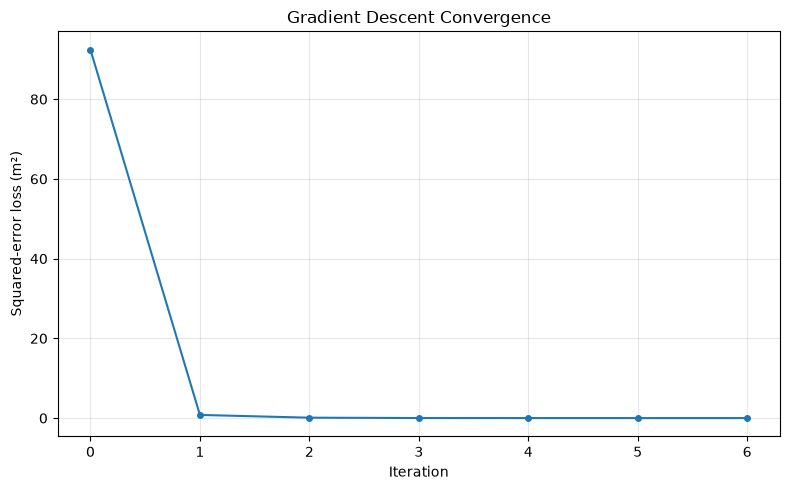

In [20]:
import matplotlib.pyplot as plt

# Extract iteration numbers and loss values from the optimization history
iterations = [record[0] for record in gd_history]
losses = [record[2] for record in gd_history]

# Plot the loss function over successive iterations
plt.figure(figsize=(8, 5))
plt.plot(iterations, losses, marker="o", markersize=4)

# Add descriptive labels and a title
plt.xlabel("Iteration")
plt.ylabel("Squared-error loss (m²)")
plt.title("Gradient Descent Convergence")

# Add a grid to make changes in the loss easier to observe
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


##### Initial Results and Observations

The initial experiment demonstrates the application of Gradient Descent to the automatic aiming problem.

The iteration history and convergence plot provide information about how the launch angle and squared-error loss change during optimization.

The final absolute distance error is compared with the specified tolerance of 0.01 meters to determine whether the target has been reached successfully.

This experiment serves as an initial verification of the implementation. A more systematic evaluation of different learning rates, starting angles, and convergence behavior will be presented in Section 4.

### 3.5 Experimental Setup

The experiments are designed to evaluate the accuracy of Euler's numerical method and the effectiveness of Gradient Descent for automatic projectile aiming.

All experiments use the same idealized projectile motion model described in Section 3.1, with constant gravitational acceleration, no air resistance, and equal launch and landing heights.

Two groups of experiments are conducted.

#### 3.5.1 Euler Method Experiments

The first group investigates how the time step affects the accuracy of Euler's method.

The analytical solution from Section 3.2 is used as a reference.

The following parameters are kept constant:

| Parameter | Value |
|---|---|
| Initial speed ($v_0$) | 20 m/s |
| Launch angle ($\theta$) | 45° |
| Gravitational acceleration ($g$) | 9.81 m/s² |

The numerical simulation is repeated using different time steps:

$$
h \in \{0.5,\ 0.2,\ 0.1,\ 0.05,\ 0.01\}\text{ seconds}
$$

For each time step, the following quantities are recorded:

- Estimated flight time.
- Estimated horizontal range.
- Absolute error in horizontal range compared with the analytical solution.
- Absolute error in flight time compared with the analytical solution.

The results will show how reducing the time step affects numerical accuracy.

#### 3.5.2 Gradient Descent Experiments

The second group evaluates the effectiveness of Gradient Descent in finding a suitable launch angle.

The following parameters are kept constant:

| Parameter | Value |
|---|---|
| Initial speed ($v_0$) | 20 m/s |
| Target distance ($D$) | 30 m |
| Gravitational acceleration ($g$) | 9.81 m/s² |
| Maximum iterations | 1000 |
| Distance tolerance | 0.01 m |

Two factors are investigated separately.

**Experiment A: Influence of the Learning Rate**

The initial angle is fixed at 15°, while the learning rate is varied:

$$
\alpha \in \{0.00001,\ 0.00005,\ 0.0001,\ 0.0005\}
$$

The experiment examines how the learning rate affects convergence speed, final accuracy, and optimization stability.

**Experiment B: Influence of the Initial Angle**

The learning rate is fixed at 0.0001, while the starting angle is varied:

$$
\theta_0 \in \{10^\circ,\ 15^\circ,\ 30^\circ,\ 45^\circ,\ 60^\circ,\ 75^\circ\}
$$

This experiment investigates how the initial angle influences the optimization result, including convergence toward different valid trajectories and possible failure at stationary points.

For each run, the following results are recorded:

- Final optimized angle.
- Achieved horizontal range.
- Absolute distance error.
- Number of iterations.
- Whether the target was reached within the specified tolerance.

#### 3.5.3 Evaluation Criteria

The two numerical methods are evaluated using different criteria.

**Euler's method** is evaluated primarily by its numerical accuracy. Smaller differences between the numerical and analytical results indicate better accuracy.

**Gradient Descent** is evaluated by its ability to reach the target within the specified tolerance, the number of iterations required, and its sensitivity to the learning rate and initial angle.

The numerical results, comparison tables, and visualizations are presented in Section 4.

## 4. Evaluation

This section presents the experimental evaluation of the two numerical methods implemented in Section 3: Euler's method for projectile motion simulation and Gradient Descent for automatic aiming.

The experiments follow the setup described in Section 3.5.

The evaluation focuses on two main questions:

- **Numerical accuracy:** How does the time step affect the accuracy of Euler's method compared with the analytical solution?
- **Optimization performance:** How do the learning rate and initial launch angle influence the accuracy and convergence of Gradient Descent?

The results are presented using numerical comparisons, tables, visualizations, and observations. Each experiment is followed by a discussion of its results and their implications.

### 4.1 Euler Method Accuracy Evaluation

The first experiment evaluates the numerical accuracy of Euler's method by comparing its results with the analytical solution of projectile motion.

As described in Section 3.5.1, the initial speed is fixed at 20 m/s, the launch angle at 45°, and gravitational acceleration at 9.81 m/s².

The Euler simulation is repeated using five different time steps:

$$
h \in \{0.5,\ 0.2,\ 0.1,\ 0.05,\ 0.01\}\text{ s}
$$

For each simulation, the estimated flight time and horizontal range are compared with the corresponding analytical values.

The absolute errors are calculated as:

$$
\text{Range Error} = |R_{\text{Euler}}-R_{\text{Analytical}}|
$$

$$
\text{Flight Time Error} = |T_{\text{Euler}}-T_{\text{Analytical}}|
$$

The purpose of this experiment is to investigate whether smaller time steps produce more accurate numerical results and to observe the convergence behavior of Euler's method.

The results will be presented in a comparison table and visualized to illustrate the relationship between time step size and numerical error.

#### 4.1.1 Experimental Implementation

The Euler simulation is executed using five different time steps while keeping the initial speed, launch angle, and gravitational acceleration constant.

For each simulation, the estimated flight time and horizontal range are recorded. The analytical solution is calculated using the equations derived in Section 3.2 and serves as the reference for evaluating numerical accuracy.

The following Python code performs the simulations and calculates the absolute errors for each time step.

In [21]:
import numpy as np

# Define the fixed parameters for the experiment
v0 = 20.0
angle_deg = 45.0
g = 9.81

# Define the time steps to be evaluated
time_steps = [0.5, 0.2, 0.1, 0.05, 0.01]

# Convert the launch angle from degrees to radians
theta = np.radians(angle_deg)

# Calculate the analytical reference values
analytical_time = 2 * v0 * np.sin(theta) / g
analytical_range = (v0**2 / g) * np.sin(2 * theta)

# Store the results of each numerical simulation
euler_results = []

# Run the Euler simulation for each time step
for h in time_steps:
    times, xs, ys = simulate_euler(v0, angle_deg, h, g)

    # Extract the estimated landing time and horizontal range
    euler_time = times[-1]
    euler_range = xs[-1]

    # Calculate absolute errors relative to the analytical solution
    time_error = abs(euler_time - analytical_time)
    range_error = abs(euler_range - analytical_range)

    # Store the results for comparison and visualization
    euler_results.append({
        "h": h,
        "flight_time": euler_time,
        "range": euler_range,
        "time_error": time_error,
        "range_error": range_error
    })

# Display the analytical reference values
print(f"Analytical flight time: {analytical_time:.6f} s")
print(f"Analytical range: {analytical_range:.6f} m")

Analytical flight time: 2.883208 s
Analytical range: 40.774720 m


#### 4.1.2 Comparison of Numerical Results

The following table compares the numerical results obtained with Euler's method against the analytical solution.

For each time step, the table displays the estimated flight time, horizontal range, and their corresponding absolute errors.

This comparison allows us to evaluate how the numerical accuracy changes as the time step decreases.

In [22]:
# Print the table header
print(
    f"{'Step (s)':<12}"
    f"{'Time (s)':<14}"
    f"{'Time Error (s)':<18}"
    f"{'Range (m)':<14}"
    f"{'Range Error (m)':<18}"
)

print("-" * 76)

# Display the results for each time step
for result in euler_results:
    print(
        f"{result['h']:<12.3f}"
        f"{result['flight_time']:<14.6f}"
        f"{result['time_error']:<18.6f}"
        f"{result['range']:<14.6f}"
        f"{result['range_error']:<18.6f}"
    )

Step (s)    Time (s)      Time Error (s)    Range (m)     Range Error (m)   
----------------------------------------------------------------------------
0.500       3.368849      0.485640          47.642713     6.867994          
0.200       3.080090      0.196882          43.559052     2.784333          
0.100       2.982729      0.099521          42.182159     1.407439          
0.050       2.933017      0.049809          41.479123     0.704403          
0.010       2.893201      0.009992          40.916035     0.141315          


#### 4.1.3 Error Visualization

To visualize the relationship between time step size and numerical accuracy, the absolute errors in horizontal range and flight time are plotted against the time step.

Both errors are expected to decrease as the time step becomes smaller.

The plots help illustrate the convergence of Euler's method toward the analytical solution.

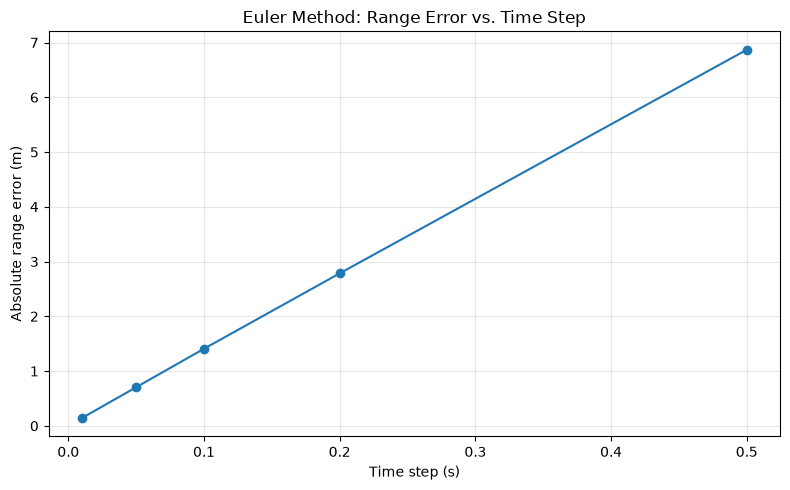

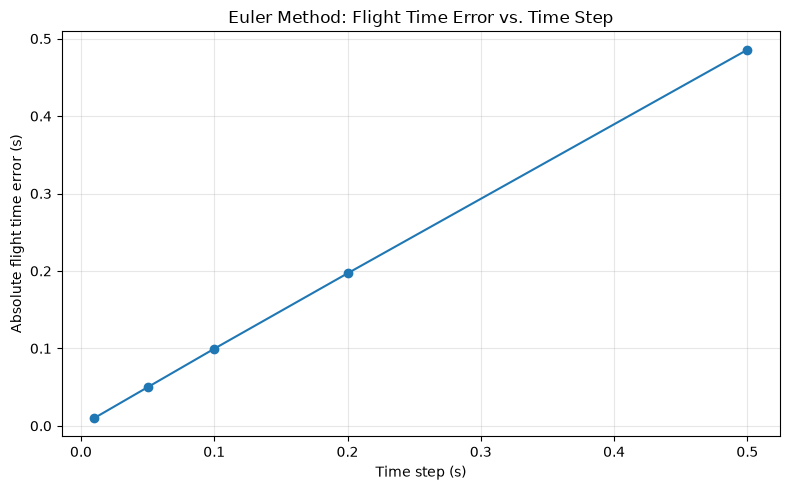

In [23]:
import matplotlib.pyplot as plt

# Extract time steps and errors from the experiment results
steps = [result["h"] for result in euler_results]
range_errors = [result["range_error"] for result in euler_results]
time_errors = [result["time_error"] for result in euler_results]

# Plot the horizontal range error
plt.figure(figsize=(8, 5))
plt.plot(steps, range_errors, marker="o")

plt.xlabel("Time step (s)")
plt.ylabel("Absolute range error (m)")
plt.title("Euler Method: Range Error vs. Time Step")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot the flight time error
plt.figure(figsize=(8, 5))
plt.plot(steps, time_errors, marker="o")

plt.xlabel("Time step (s)")
plt.ylabel("Absolute flight time error (s)")
plt.title("Euler Method: Flight Time Error vs. Time Step")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 4.1.4 Results and Observations

The experimental results demonstrate that the accuracy of Euler's method improves as the time step decreases.

With a time step of **0.5 seconds**, the absolute horizontal range error is approximately **6.868 meters**, while the flight time error is approximately **0.486 seconds**.

When the time step is reduced to **0.01 seconds**, the range error decreases to approximately **0.141 meters**, and the flight time error decreases to approximately **0.010 seconds**.

The numerical results consistently overestimate both the flight time and horizontal range. This behavior is caused by the explicit Euler method using the vertical velocity at the beginning of each time step to update the projectile's position.

The two error plots show an approximately linear relationship between time step size and numerical error. For example, reducing the time step from 0.1 to 0.05 seconds reduces the range error from approximately 1.407 meters to 0.704 meters.

This behavior is consistent with the **first-order global accuracy of Euler's method**, where the numerical error is proportional to the time step.

The experiment confirms the initial hypothesis that smaller time steps improve numerical accuracy. However, smaller time steps also require more simulation steps, creating a trade-off between computational efficiency and precision.

Overall, Euler's method provides a simple and effective numerical approximation of projectile motion, although its accuracy depends strongly on the selected time step.

## 6. References

[1] OpenStax. *University Physics Volume 1, Section 4.3: Projectile Motion.*  
https://openstax.org/books/university-physics-volume-1/pages/4-3-projectile-motion

[2] OpenStax. *University Physics Volume 1, Section 5.3: Newton's Second Law.*  
https://openstax.org/books/university-physics-volume-1/pages/5-3-newtons-second-law

[3] Chasnov, J. R. *Numerical Methods, Section 7.2: Numerical Methods — Initial Value Problem.* Mathematics LibreTexts.  
https://math.libretexts.org/Bookshelves/Applied_Mathematics/Numerical_Methods_%28Chasnov%29/07%3A_Ordinary_Differential_Equations/7.02%3A_Numerical_Methods_-_Initial_Value_Problem

[4] Cornell University. *CS 4220: Numerical Analysis — Gradient Descent.* 2026.  
https://www.cs.cornell.edu/courses/cs4220/2026sp/lec/2026-04-08.html